In [13]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import mean_squared_error
import numpy as np

In [14]:
merton = pd.read_csv('Merton.csv')
cg = pd.read_csv('CreditGrades.csv')

In [15]:
df = merton.merge(cg[['Date', 'CG_IV']], on = 'Date', how = 'inner')

In [16]:
df.head(2)

,Unnamed: 0,Date,Z_spread,Merton_IV,Merton_GARCH,CG_IV
0,503,2018-01-02,109.249072,0.348368,0.000038,1.050279
1,504,2018-01-03,107.415780,0.276773,0.000022,0.858552


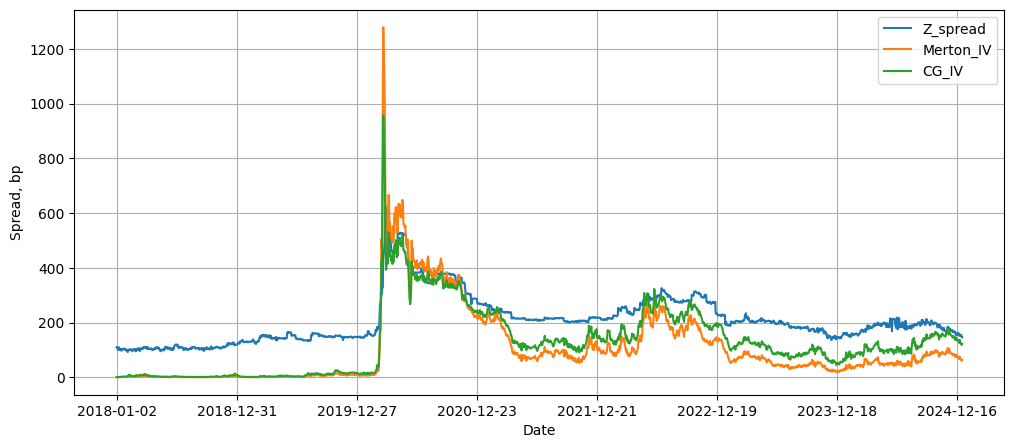

In [18]:
ax = df.plot(x="Date", y=["Z_spread", "Merton_IV", "CG_IV"],
                 figsize=(12, 5), grid=True)
ax.set_ylabel("Spread, bp")
plt.show()

In [20]:
for col in ['Merton_IV', 'CG_IV']:
    mse = mean_squared_error(df['Z_spread'], df[col])
    ll = -len(df) / 2 * (np.log(2 * np.pi * mse) + 1)
    print(col, 'MSE:', mse, 'LogLik:', ll)

Merton_IV MSE: 15257.010883418327 LogLik: -10980.426231854668
CG_IV MSE: 8900.875080792985 LogLik: -10505.933999033528
